<a href="https://colab.research.google.com/github/crisriverar/An-lisis-de-mortalidad-vial-en-Cali-2016-2023-/blob/main/Proyecto_accidentes_de_tr%C3%A1nsito_en_Cali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 50)
df = pd.read_csv("/content/consolidado_muertes_en_accidente_de_ransito_2016_al_2023.csv", encoding="latin-1", sep=";")

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2456 entries, 0 to 2455
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   SEXO         2456 non-null   object
 1   EDAD         2456 non-null   object
 2   HORA HECHO   2456 non-null   object
 3   FECHA HECHO  2456 non-null   object
 4   FECHA FALL.  2456 non-null   object
 5   CONDICION    2456 non-null   object
dtypes: object(6)
memory usage: 115.3+ KB


In [9]:
df["EDAD"].unique()

array(['22', '28', '25', '20', '67', '24', '27', '32', '34', '79', '63',
       '18', '46', '57', '58', '.', '61', '17', '21', '29', '45', '60',
       '43', '62', '33', '19', '59', '31', '75', '51', '73', '30', '78',
       '65', '26', '23', '64', '41', '91', '35', '85', '68', '70', '48',
       '52', '39', '53', '15', '14', '74', '55', '56', '44', '40', '84',
       '76', '36', '49', '16', '54', '69', '77', '83', '47', '80', '38',
       '86', '72', '89', '12', '82', '71', '42', '66', '50', '13', '87',
       '37', '11', '81', '3', '88', '90', '95', '1', '2', '23h', '5',
       '2M', '93', '35-45', '40-45', '25-30', '9', '92'], dtype=object)

In [10]:
df[df["EDAD"] == "23h"]

,SEXO,EDAD,HORA HECHO,FECHA HECHO,FECHA FALL.,CONDICION
1164,Femenino,23h,9:30,22/07/2019,23/07/2019,Pasajero de Auto


In [11]:
edad_numerica = pd.to_numeric(df["EDAD"], errors="coerce")
valores_problematicos = df.loc[edad_numerica.isna(), "EDAD"].unique()
print(valores_problematicos)

['.' '23h' '2M' '35-45' '40-45' '25-30']


In [50]:
import re

def limpiar_edad(valor):
    if valor == ".":
        return np.nan

    if valor.endswith("h"):
        numero = re.findall(r"\d+", valor)[0]
        return int(numero) / 8760

    if valor.endswith("M"):
      numero = re.findall(r"\d+",valor)[0]
      return int(numero)/12

    if "-" in valor:
      numero= re.findall(r"\d+",valor)[0:2]
      return sum(map(int, numero))/len(numero)

    return float(valor)

df["edad_limpia"] = df["EDAD"].apply(limpiar_edad)

In [13]:
print(df["edad_limpia"].dtype)
df["edad_limpia"].describe()

float64


,edad_limpia
count,2438.000000
mean,46.976690
std,21.640289
min,0.002626
25%,26.000000
50%,45.500000
75%,65.000000
max,95.000000


In [14]:
df["SEXO"].unique()

array(['Masculino', 'Femenino', 'Femenina'], dtype=object)

In [51]:
df["SEXO"] = df["SEXO"].replace("Femenina", "Femenino")
df["SEXO"].unique()

array(['Masculino', 'Femenino'], dtype=object)

In [16]:
df["CONDICION"].unique()

array(['Motociclista', 'Peatón', 'Parrillero', 'Ciclista', 'Sin dato',
       'Conductor', 'Pasajero de Auto', 'Jinete', 'ciclista'],
      dtype=object)

In [17]:
df["CONDICION"] = df["CONDICION"].replace("ciclista", "Ciclista")
df["CONDICION"].unique()

array(['Motociclista', 'Peatón', 'Parrillero', 'Ciclista', 'Sin dato',
       'Conductor', 'Pasajero de Auto', 'Jinete'], dtype=object)

In [18]:
df["CONDICION"].apply(lambda x: repr(x)).unique()

array(["'Motociclista'", "'Peatón'", "'Parrillero'", "'Ciclista'",
       "'Sin dato'", "'Conductor'", "'Pasajero de Auto'", "'Jinete'"],
      dtype=object)

In [19]:
print("Cantidad de sin dato:",df["CONDICION"].isin(["Sin dato"]).sum())
print("Proporción sin dato:",df["CONDICION"].isin(["Sin dato"]).mean().round(3))


Cantidad de sin dato: 24
Proporción sin dato: 0.01


In [20]:
df["CONDICION"] = df["CONDICION"].replace("Sin dato",np.nan)
df["CONDICION"].unique()

array(['Motociclista', 'Peatón', 'Parrillero', 'Ciclista', nan,
       'Conductor', 'Pasajero de Auto', 'Jinete'], dtype=object)

In [21]:
df["FECHA HECHO"] = pd.to_datetime(df["FECHA HECHO"], dayfirst=True, errors="coerce")
df["FECHA HECHO"].dt.year.value_counts()

,count
FECHA HECHO,
2018.0,353
2016.0,323
2022.0,323
2017.0,322
2019.0,300
2020.0,298
2021.0,289
2023.0,79


In [22]:
df["FECHA FALL."] = pd.to_datetime(df["FECHA FALL."], dayfirst=True, errors="coerce")
df['FECHA FALL.'].dt.year.value_counts()

,count
FECHA FALL.,
2018.0,348
2022.0,325
2017.0,319
2016.0,318
2019.0,315
2020.0,297
2021.0,297
2023.0,233


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2456 entries, 0 to 2455
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   SEXO         2456 non-null   object        
 1   EDAD         2456 non-null   object        
 2   HORA HECHO   2456 non-null   object        
 3   FECHA HECHO  2287 non-null   datetime64[ns]
 4   FECHA FALL.  2452 non-null   datetime64[ns]
 5   CONDICION    2432 non-null   object        
 6   edad_limpia  2438 non-null   float64       
dtypes: datetime64[ns](2), float64(1), object(4)
memory usage: 134.4+ KB


In [24]:
df["dias_hasta_fallecer"] = (df["FECHA FALL."] - df["FECHA HECHO"]).dt.days

In [25]:
df["dias_hasta_fallecer"].describe()

,dias_hasta_fallecer
count,2283.000000
mean,7.201927
std,35.597356
min,-365.000000
25%,0.000000
50%,0.000000
75%,4.000000
max,600.000000


In [26]:
df["año"] = df["FECHA HECHO"].dt.year
df["mes"] = df["FECHA HECHO"].dt.month
df["dia_semana"] = df["FECHA HECHO"].dt.day_name()

In [27]:
fechas_invalidas= df[(df["dias_hasta_fallecer"] < 0 ) |(df["dias_hasta_fallecer"] > 90) ]
print(f"Filas con fechas invalidas: {len(fechas_invalidas)}")

Filas con fechas invalidas: 69


In [28]:
negativos = df[df["dias_hasta_fallecer"] < 0]
print(f"Filas con días negativos: {len(negativos)}")

Filas con días negativos: 26


In [29]:
extremos = df[df["dias_hasta_fallecer"] > 90]
print(f"Filas con más de 90 días: {len(extremos)}")

Filas con más de 90 días: 43


In [30]:
negativos[["FECHA HECHO", "FECHA FALL.", "dias_hasta_fallecer"]]

,FECHA HECHO,FECHA FALL.,dias_hasta_fallecer
31,2016-02-28,2016-02-04,-24.0
39,2017-02-08,2016-02-11,-363.0
150,2017-06-20,2016-06-21,-364.0
152,2016-06-25,2016-06-24,-1.0
267,2016-12-04,2016-11-06,-28.0
272,2016-11-28,2016-11-16,-12.0
286,2016-11-28,2016-11-26,-2.0
406,2018-04-08,2017-04-08,-365.0
449,2017-05-30,2017-05-29,-1.0
473,2017-07-06,2017-07-05,-1.0


In [31]:
extremos[["FECHA HECHO", "FECHA FALL.", "dias_hasta_fallecer"]]

,FECHA HECHO,FECHA FALL.,dias_hasta_fallecer
236,2016-01-30,2016-09-30,244.0
239,2016-05-30,2016-10-08,131.0
412,2016-12-07,2017-04-23,137.0
466,2017-01-23,2017-06-18,146.0
564,2017-05-27,2017-10-16,142.0
580,2017-06-23,2017-10-31,130.0
586,2016-06-07,2017-11-05,516.0
603,2017-02-22,2017-11-26,277.0
605,2017-03-17,2017-11-27,255.0
623,2017-08-16,2017-12-12,118.0


In [32]:
df["dias_hasta_fallecer_valido"] = df["dias_hasta_fallecer"].where((df["dias_hasta_fallecer"] >= 0) & (df["dias_hasta_fallecer"] <= 30))

In [33]:
print(f"Valores válidos: {df['dias_hasta_fallecer_valido'].notna().sum()}")
print(f"Valores invalidados: {df['dias_hasta_fallecer_valido'].isna().sum() - df['dias_hasta_fallecer'].isna().sum()}")
df["dias_hasta_fallecer_valido"].describe()

Valores válidos: 2109
Valores invalidados: 174


,dias_hasta_fallecer_valido
count,2109.000000
mean,2.719772
std,5.356432
min,0.000000
25%,0.000000
50%,0.000000
75%,3.000000
max,30.000000


In [34]:
print(df["HORA HECHO"].unique()[:20])

['.' '6:40' '15:30' '6:50' '6:15' '6:30' '10:42' '7:35' '21:15' '22:50'
 '10:38' '18:15' '13:05' '11:45' '4:05' '11:36' '3:30' '0:05' '6:45'
 '8:50']


In [35]:
df["HORA HECHO"] = df['HORA HECHO'].replace('.',np.nan)
print(df['HORA HECHO'].unique()[:20])


[nan '6:40' '15:30' '6:50' '6:15' '6:30' '10:42' '7:35' '21:15' '22:50'
 '10:38' '18:15' '13:05' '11:45' '4:05' '11:36' '3:30' '0:05' '6:45'
 '8:50']


In [36]:
df["hora_num"] = pd.to_datetime(df["HORA HECHO"], format="%H:%M", errors="coerce").dt.hour
df["hora_num"].describe()

,hora_num
count,2041.000000
mean,12.315532
std,6.893688
min,0.000000
25%,6.000000
50%,13.000000
75%,18.000000
max,23.000000


In [37]:
def franja_horaria(hora):
    if pd.isna(hora):
        return pd.NA
    elif 0 <= hora < 6:
        return "Madrugada"
    elif 6 <= hora < 12:
        return "Mañana"
    elif 12 <= hora < 18:
        return "Tarde"
    elif 18 <= hora < 24:
        return "Noche"
    else:
        return pd.NA

df["franja_horaria"] = df["hora_num"].apply(franja_horaria)
df["franja_horaria"].value_counts()

,count
franja_horaria,
Noche,621
Mañana,499
Tarde,498
Madrugada,423


In [38]:
df["CONDICION"].value_counts()
df["CONDICION"].value_counts(normalize=True).round(3) * 100

,proportion
CONDICION,
Motociclista,41.1
Peatón,38.9
Ciclista,9.6
Parrillero,6.4
Pasajero de Auto,2.1
Conductor,1.9
Jinete,0.0


In [39]:
df.groupby("CONDICION")["edad_limpia"].agg(["count", "mean", "median", "std"]).round(1).sort_values("mean")

,count,mean,median,std
CONDICION,,,,
Parrillero,154,33.3,28.0,17.8
Motociclista,994,33.8,29.0,14.4
Jinete,1,35.0,35.0,NaN
Conductor,45,41.8,34.0,18.6
Pasajero de Auto,51,42.9,41.0,23.0
Ciclista,234,52.9,59.0,19.9
Peatón,937,62.3,66.0,18.2


In [40]:
peatones = df[df["CONDICION"] == "Peatón"]
peatones["edad_limpia"].describe()

,edad_limpia
count,937.000000
mean,62.316969
std,18.234212
min,1.000000
25%,51.000000
50%,66.000000
75%,77.000000
max,95.000000


In [41]:
peatones[peatones["edad_limpia"] < 12][["edad_limpia", "SEXO"]]

,edad_limpia,SEXO
887,1.0,Masculino
1488,5.0,Masculino
2065,5.0,Masculino
2330,3.0,Femenino


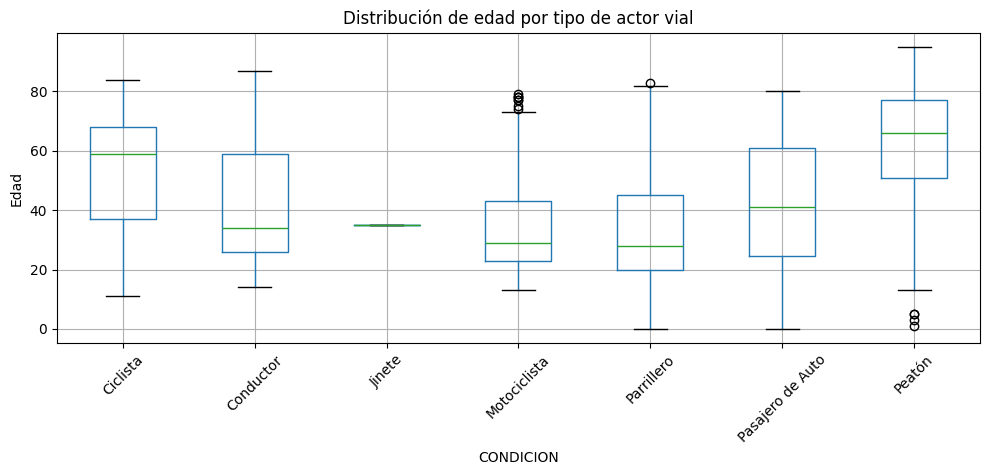

In [42]:
df.boxplot(column="edad_limpia", by="CONDICION", figsize=(10,5))
plt.xticks(rotation=45)
plt.title("Distribución de edad por tipo de actor vial")
plt.suptitle("")
plt.ylabel("Edad")
plt.tight_layout()
plt.show()

In [43]:
peatones_jovenes= df[(df["CONDICION"] == "Peatón") & (df["edad_limpia"] < 12)]
peatones_jovenes[["edad_limpia", "SEXO"]]

,edad_limpia,SEXO
887,1.0,Masculino
1488,5.0,Masculino
2065,5.0,Masculino
2330,3.0,Femenino


In [44]:
tabla= pd.crosstab(df["SEXO"],df['CONDICION'],normalize="index")
tabla

CONDICION,Ciclista,Conductor,Jinete,Motociclista,Parrillero,Pasajero de Auto,Peatón
SEXO,,,,,,,
Femenino,0.013129,0.002188,0.002188,0.214442,0.240700,0.039387,0.487965
Masculino,0.115443,0.022785,0.000000,0.456709,0.022785,0.016709,0.365570


In [45]:
tabla= pd.crosstab(df["SEXO"],df['CONDICION'],normalize="columns")
tabla

CONDICION,Ciclista,Conductor,Jinete,Motociclista,Parrillero,Pasajero de Auto,Peatón
SEXO,,,,,,,
Femenino,0.025641,0.021739,1.0,0.098,0.709677,0.352941,0.235979
Masculino,0.974359,0.978261,0.0,0.902,0.290323,0.647059,0.764021


In [46]:
df[df["año"] == 2023]["FECHA HECHO"].max()

Timestamp('2023-04-09 00:00:00')

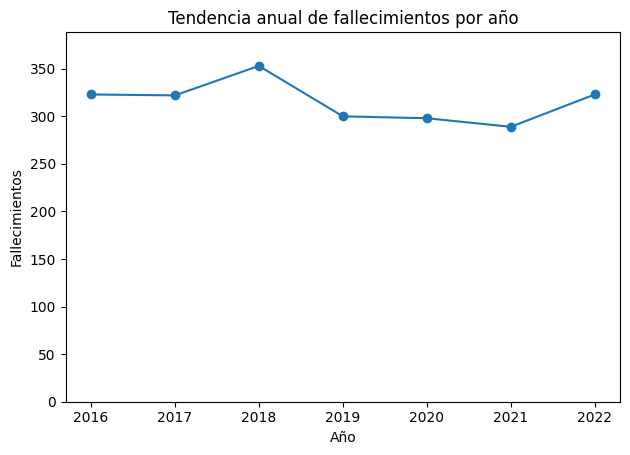

In [47]:
conteo_anual = df.groupby("año").size()
conteo_anual[conteo_anual.index != 2023].plot(kind="line", marker="o")
plt.title("Tendencia anual de fallecimientos por año")
plt.suptitle("")
plt.ylabel("Fallecimientos")
plt.xlabel("Año")
plt.tight_layout()
plt.ylim(0, conteo_anual.max() * 1.1)
plt.show()

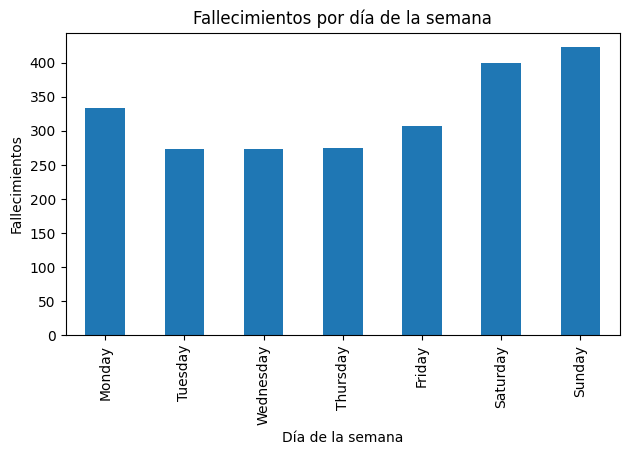

In [48]:
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
conteo_diario = df.groupby("dia_semana").size()
conteo_diario = conteo_diario.reindex(orden_dias)
conteo_diario.plot(kind="bar")
plt.title("Fallecimientos por día de la semana")
plt.suptitle("")
plt.ylabel("Fallecimientos")
plt.xlabel("Día de la semana")
plt.tight_layout()
plt.show()

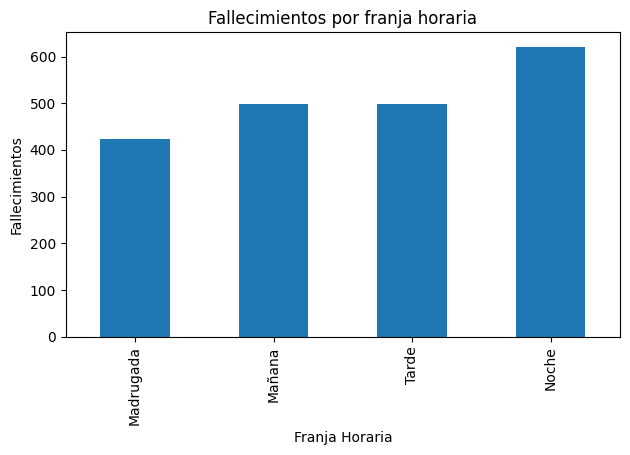

In [49]:
orden_franja = ["Madrugada", "Mañana","Tarde","Noche"]
conteo_franja = df.groupby("franja_horaria").size()
conteo_franja = conteo_franja.reindex(orden_franja)
conteo_franja.plot(kind="bar")
plt.title("Fallecimientos por franja horaria")
plt.suptitle("")
plt.ylabel("Fallecimientos")
plt.xlabel("Franja Horaria")
plt.tight_layout()
plt.show()